## Homework 4

### Data Preparation

In [1]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
zip_file = '/content/Homework 3, 4 Data.zip'

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content')

base_path = '/content/AReM'

os.listdir(base_path)

['sitting',
 'bending1',
 'bendingType.pdf',
 'standing',
 'lying',
 'bending2',
 'walking',
 'cycling',
 'sensorsPlacement.pdf']

### 2(a)(i) Binary Classification Using Logistic Regression

Create the training feature table using the selected time-domain features (minimum, mean, and maximum) from time series 1, 2, and 6.

In [3]:
column_names = [
    'time',
    'avg_rss12',
    'var_rss12',
    'avg_rss13',
    'var_rss13',
    'avg_rss23',
    'var_rss23'
]

folders = [
    'bending1',
    'bending2',
    'cycling',
    'lying',
    'sitting',
    'standing',
    'walking'
]

train_rows = []

for folder in folders:
    folder_path = os.path.join(base_path, folder)

    files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

    for file in files:

        if folder in ['bending1', 'bending2']:
            if file in ['dataset1.csv', 'dataset2.csv']:
                continue
        else:
            if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                continue

        file_path = os.path.join(folder_path, file)

        if folder == 'bending2' and file == 'dataset4.csv':
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                sep=r'\s+'
            )
        else:
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                usecols=range(7)
            )

        row = [
            df['avg_rss12'].min(),
            df['avg_rss12'].mean(),
            df['avg_rss12'].max(),

            df['var_rss12'].min(),
            df['var_rss12'].mean(),
            df['var_rss12'].max(),

            df['var_rss23'].min(),
            df['var_rss23'].mean(),
            df['var_rss23'].max(),

            'bending' if folder in ['bending1', 'bending2'] else 'other'
        ]

        train_rows.append(row)

train_features = pd.DataFrame(
    train_rows,
    columns=[
        'min1', 'mean1', 'max1',
        'min2', 'mean2', 'max2',
        'min6', 'mean6', 'max6',
        'class'
    ]
)

print(train_features.shape)
print(train_features['class'].value_counts())

train_features.head()

(69, 10)
class
other      60
bending     9
Name: count, dtype: int64


,min1,mean1,max1,min2,mean2,max2,min6,mean6,max6,class
0,35.00,43.954500,47.40,0.0,0.426250,1.70,0.0,0.493292,1.79,bending
1,33.00,42.179812,47.75,0.0,0.696042,3.00,0.0,0.613521,2.18,bending
2,37.00,43.454958,48.00,0.0,0.378083,1.58,0.0,0.679646,5.26,bending
3,33.00,41.678063,45.75,0.0,0.535979,2.83,0.0,0.383292,1.79,bending
4,36.25,43.969125,48.00,0.0,0.413125,1.50,0.0,0.555312,2.96,bending


#### Scatter Plots

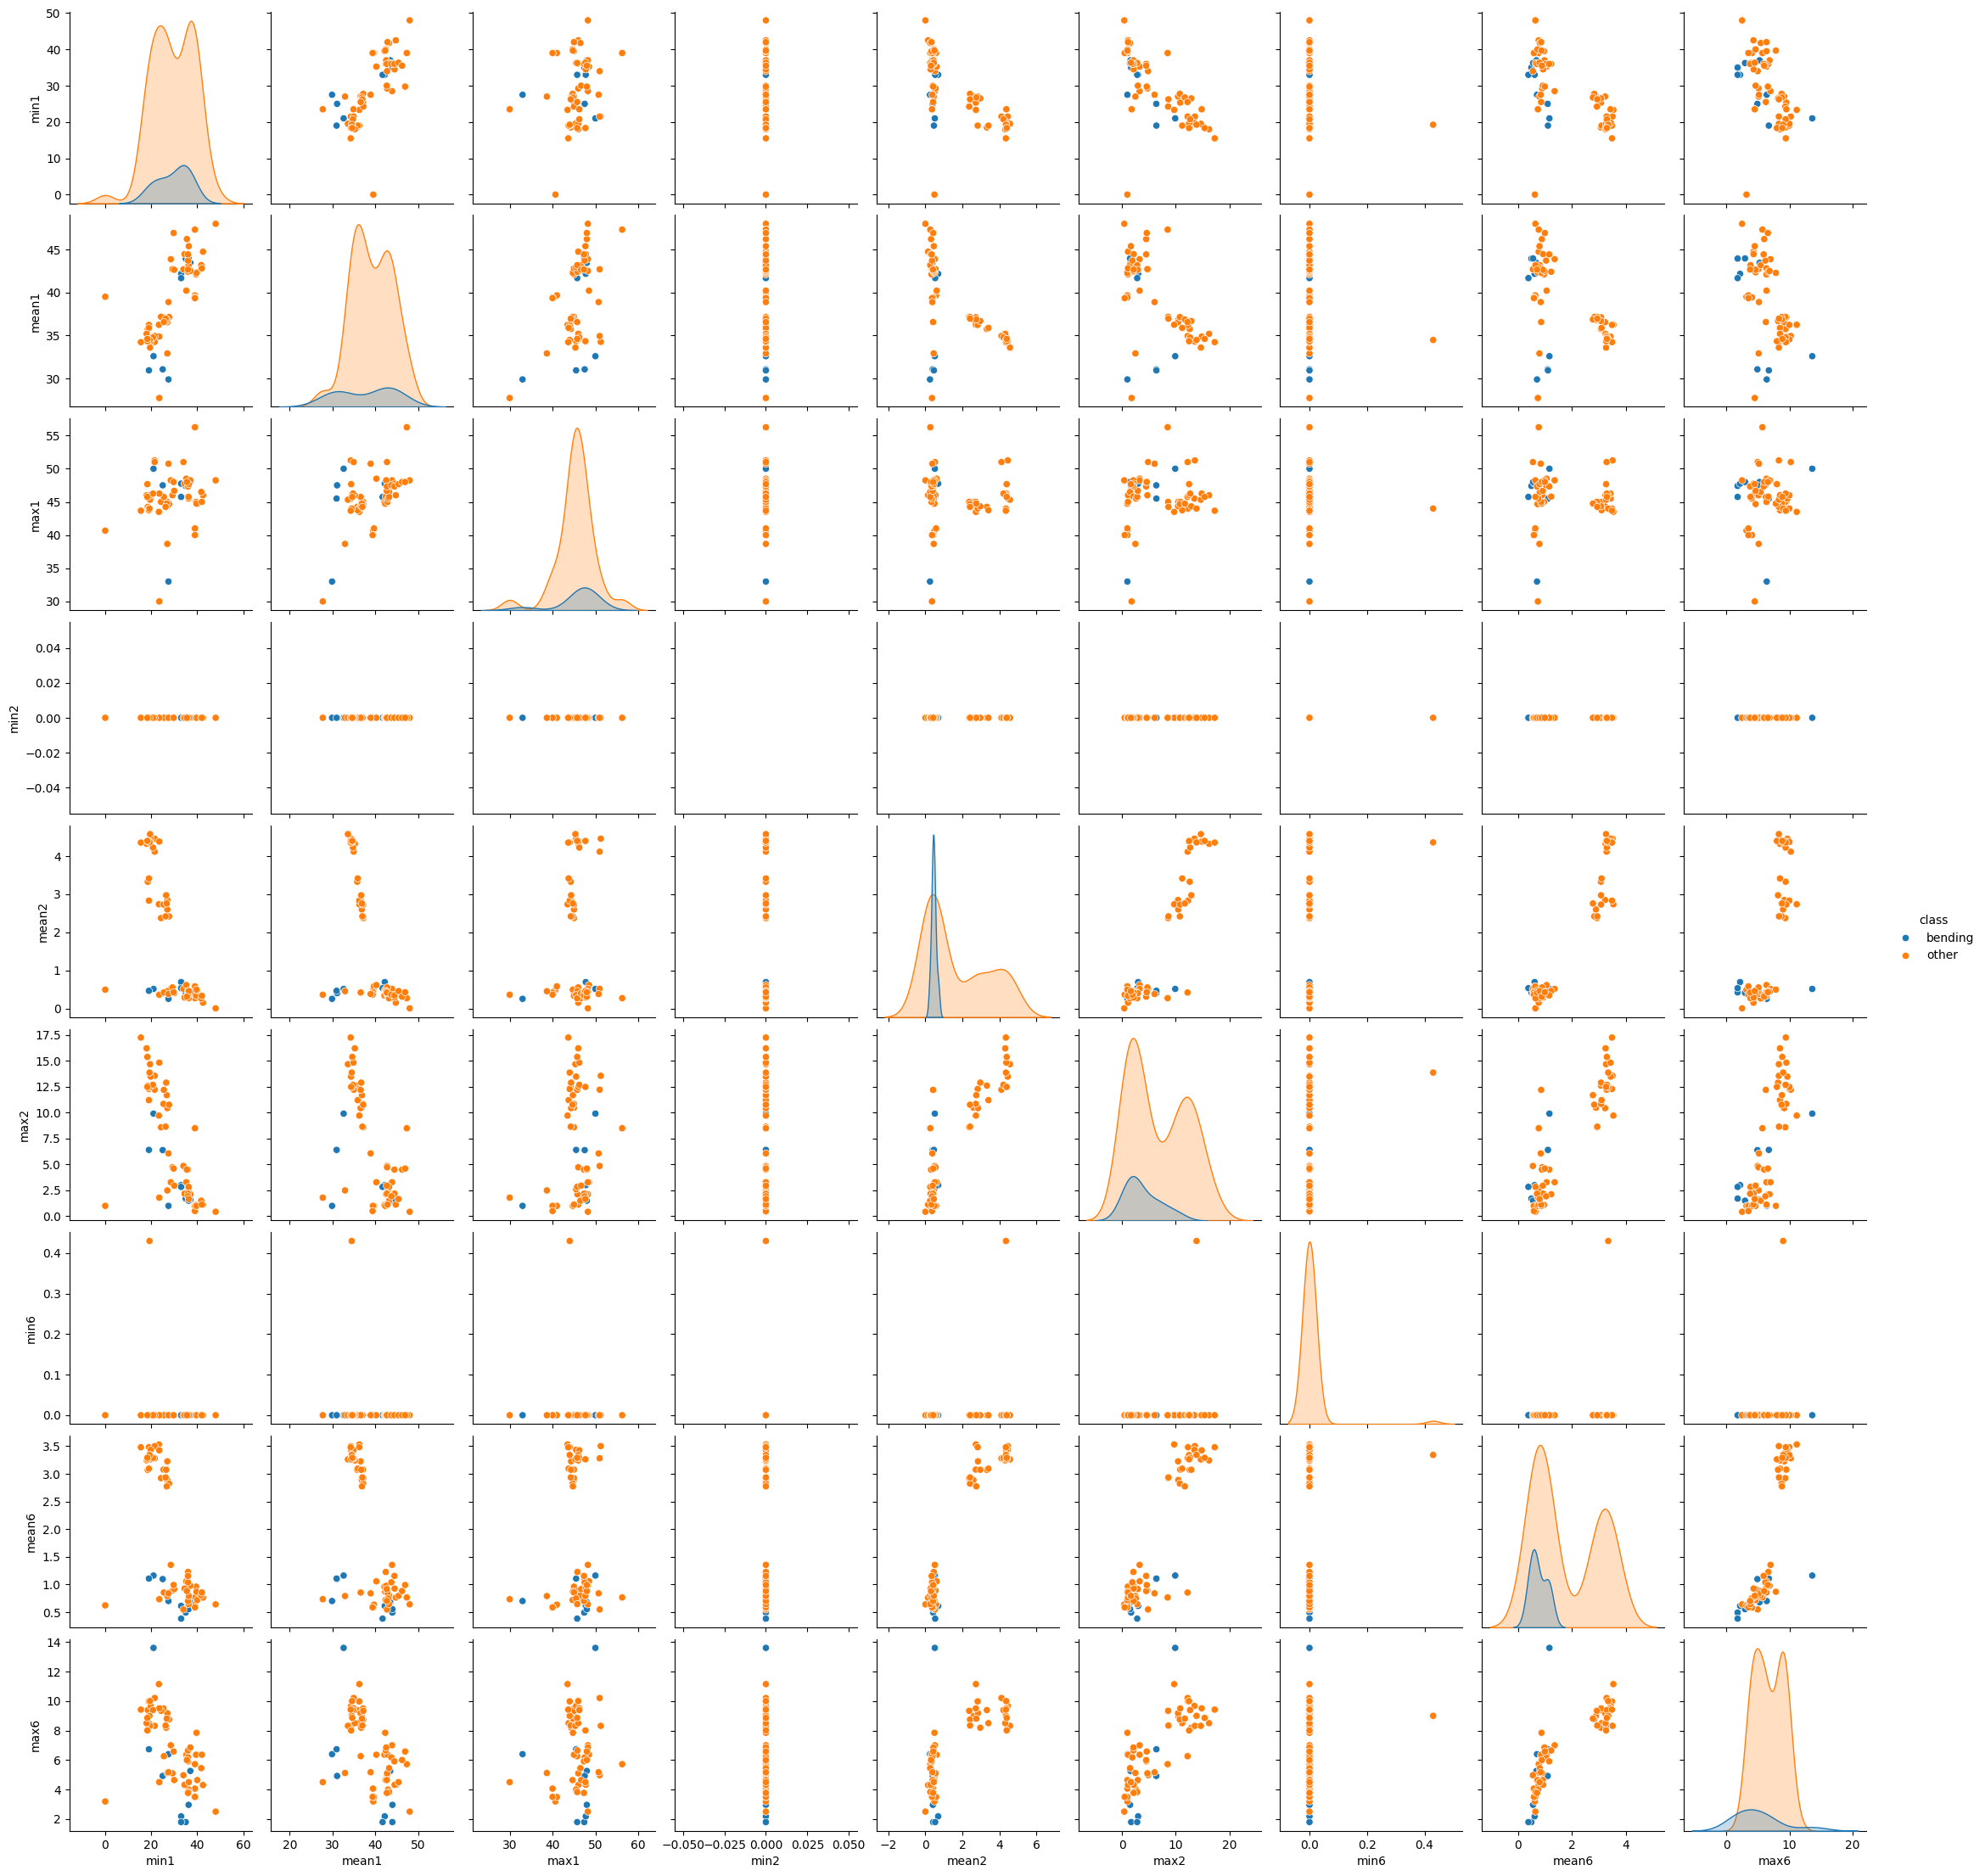

In [4]:
plot_features = [
    'min1', 'mean1', 'max1',
    'min2', 'mean2', 'max2',
    'min6', 'mean6', 'max6'
]

sns.pairplot(
    train_features,
    vars=plot_features,
    hue='class'
)

plt.show()

### 2(a)(ii) Split Each Time Series Into Two Parts

In [5]:
split_rows = []

for folder in folders:
    folder_path = os.path.join(base_path, folder)

    files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

    for file in files:

        if folder in ['bending1', 'bending2']:
            if file in ['dataset1.csv', 'dataset2.csv']:
                continue
        else:
            if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                continue

        file_path = os.path.join(folder_path, file)

        if folder == 'bending2' and file == 'dataset4.csv':
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                sep=r'\s+'
            )
        else:
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                usecols=range(7)
            )

        middle = len(df) // 2

        part1 = df.iloc[:middle]
        part2 = df.iloc[middle:]

        row = [
            part1['avg_rss12'].min(),
            part1['avg_rss12'].mean(),
            part1['avg_rss12'].max(),

            part1['var_rss12'].min(),
            part1['var_rss12'].mean(),
            part1['var_rss12'].max(),

            part1['var_rss23'].min(),
            part1['var_rss23'].mean(),
            part1['var_rss23'].max(),

            part2['avg_rss12'].min(),
            part2['avg_rss12'].mean(),
            part2['avg_rss12'].max(),

            part2['var_rss12'].min(),
            part2['var_rss12'].mean(),
            part2['var_rss12'].max(),

            part2['var_rss23'].min(),
            part2['var_rss23'].mean(),
            part2['var_rss23'].max(),

            'bending' if folder in ['bending1', 'bending2'] else 'other'
        ]

        split_rows.append(row)

split_features = pd.DataFrame(
    split_rows,
    columns=[
        'min1_p1', 'mean1_p1', 'max1_p1',
        'min2_p1', 'mean2_p1', 'max2_p1',
        'min6_p1', 'mean6_p1', 'max6_p1',

        'min1_p2', 'mean1_p2', 'max1_p2',
        'min2_p2', 'mean2_p2', 'max2_p2',
        'min6_p2', 'mean6_p2', 'max6_p2',

        'class'
    ]
)

print(split_features.shape)
print(split_features['class'].value_counts())

split_features.head()

(69, 19)
class
other      60
bending     9
Name: count, dtype: int64


,min1_p1,mean1_p1,max1_p1,min2_p1,mean2_p1,max2_p1,min6_p1,mean6_p1,max6_p1,min1_p2,mean1_p2,max1_p2,min2_p2,mean2_p2,max2_p2,min6_p2,mean6_p2,max6_p2,class
0,36.50,44.057167,46.50,0.0,0.381042,1.50,0.0,0.598250,1.79,35.00,43.851833,47.40,0.0,0.471458,1.70,0.0,0.388333,1.50,bending
1,33.75,43.278875,47.75,0.0,0.673292,3.00,0.0,0.640958,1.53,33.00,41.080750,46.00,0.0,0.718792,2.86,0.0,0.586083,2.18,bending
2,39.00,44.117042,48.00,0.0,0.250042,1.30,0.0,0.815417,5.26,37.00,42.792875,46.50,0.0,0.506125,1.58,0.0,0.543875,4.06,bending
3,33.00,41.621208,45.75,0.0,0.623083,2.83,0.0,0.419083,1.79,39.25,41.734917,43.67,0.0,0.448875,1.12,0.0,0.347500,1.50,bending
4,36.67,43.486208,45.00,0.0,0.378667,1.30,0.0,0.524875,2.28,36.25,44.452042,48.00,0.0,0.447583,1.50,0.0,0.585750,2.96,bending


#### Scatter Plots After Splitting Each Time Series Into Two Parts

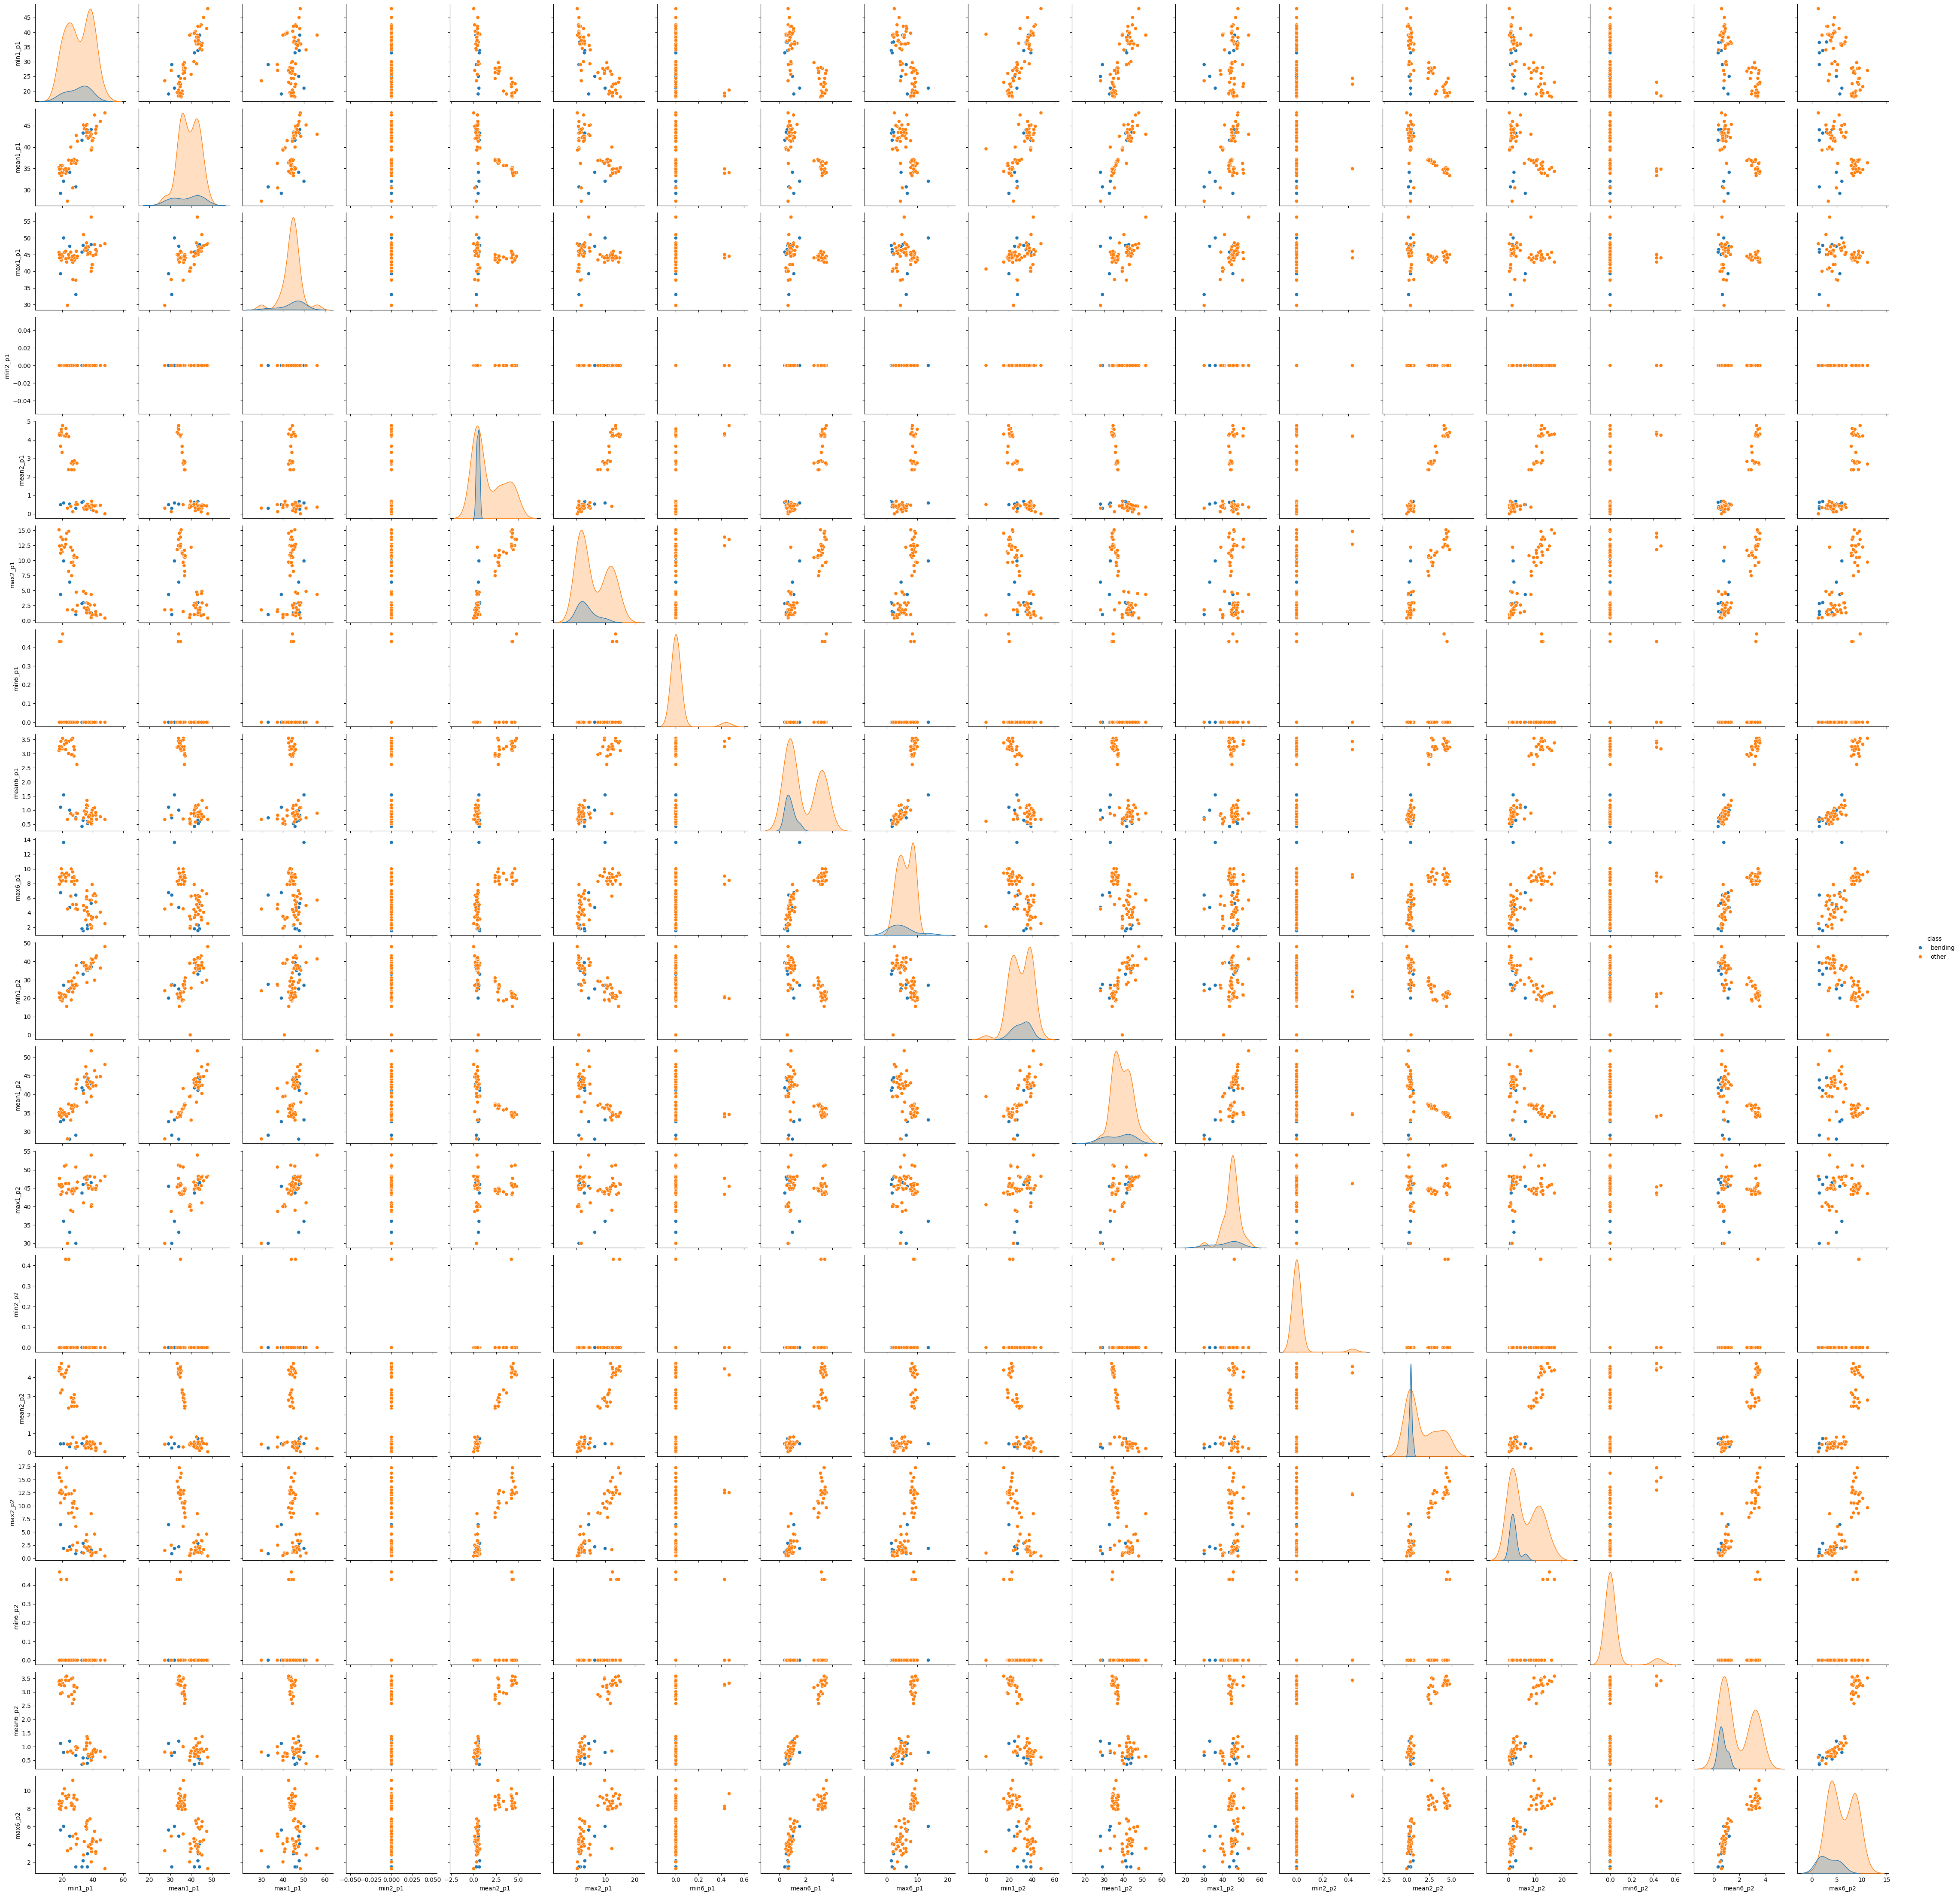

In [6]:
split_plot_features = [
    'min1_p1', 'mean1_p1', 'max1_p1',
    'min2_p1', 'mean2_p1', 'max2_p1',
    'min6_p1', 'mean6_p1', 'max6_p1',
    'min1_p2', 'mean1_p2', 'max1_p2',
    'min2_p2', 'mean2_p2', 'max2_p2',
    'min6_p2', 'mean6_p2', 'max6_p2'
]

sns.pairplot(
    split_features,
    vars=split_plot_features,
    hue='class'
)

plt.show()

After splitting each time series into two parts, the number of features increases and the scatter plots show more detailed variation within each activity. However, the overall separation between bending and other activities is generally similar to the original plots. The split features provide additional information, but there is no dramatic change in class separation.

### 2(a)(iii) Logistic Regression and Cross-Validation

In [7]:
X_by_l = []
feature_names_by_l = []
y_train = None

for l in range(1, 21):

    rows = []
    labels = []

    feature_names = []

    for part_number in range(1, l + 1):
        for series_number in range(1, 7):

            feature_names.extend([
                'min' + str(series_number) + '_part' + str(part_number),
                'max' + str(series_number) + '_part' + str(part_number),
                'mean' + str(series_number) + '_part' + str(part_number),
                'median' + str(series_number) + '_part' + str(part_number),
                'std' + str(series_number) + '_part' + str(part_number),
                'q1_' + str(series_number) + '_part' + str(part_number),
                'q3_' + str(series_number) + '_part' + str(part_number)
            ])

    for folder in folders:

        folder_path = os.path.join(base_path, folder)
        files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

        for file in files:

            if folder in ['bending1', 'bending2']:
                if file in ['dataset1.csv', 'dataset2.csv']:
                    continue
            else:
                if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                    continue

            file_path = os.path.join(folder_path, file)

            if folder == 'bending2' and file == 'dataset4.csv':
                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    sep=r'\s+'
                )
            else:
                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    usecols=range(7)
                )

            index_parts = np.array_split(np.arange(len(df)), l)

            row = []

            for indexes in index_parts:

                part = df.iloc[indexes]

                for column in column_names[1:]:

                    row.extend([
                        part[column].min(),
                        part[column].max(),
                        part[column].mean(),
                        part[column].median(),
                        part[column].std(),
                        part[column].quantile(0.25),
                        part[column].quantile(0.75)
                    ])

            rows.append(row)

            if folder in ['bending1', 'bending2']:
                labels.append(1)
            else:
                labels.append(0)

    X = pd.DataFrame(rows, columns=feature_names)

    X_by_l.append(X)
    feature_names_by_l.append(feature_names)

    if y_train is None:
        y_train = np.array(labels)

print("l = 1:", X_by_l[0].shape)
print("l = 20:", X_by_l[19].shape)
print("Labels:", y_train.shape)

l = 1: (69, 42)
l = 20: (69, 840)
Labels: (69,)


#### 5-Fold Cross-Validation and Recursive Feature Elimination

In [8]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

cv_results = []

for l in range(1, 21):

    X = X_by_l[l - 1]

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(
            C=1000000,
            solver='liblinear',
            max_iter=2000
        ))
    ])

    selector = RFECV(
        estimator=model,
        step=1,
        cv=cv,
        scoring='accuracy',
        min_features_to_select=1,
        importance_getter='named_steps.logreg.coef_',
        n_jobs=-1
    )

    selector.fit(X, y_train)

    best_p = selector.n_features_
    best_score = selector.cv_results_['mean_test_score'].max()

    cv_results.append([
        l,
        best_p,
        best_score
    ])

cv_table = pd.DataFrame(
    cv_results,
    columns=[
        'l',
        'p',
        'CV Accuracy'
    ]
)

cv_table

,l,p,CV Accuracy
0,1,2,0.957143
1,2,3,0.971429
2,3,1,0.928571
3,4,26,0.956044
4,5,2,0.941758
5,6,4,0.956044
6,7,3,0.927473
7,8,6,0.957143
8,9,2,0.927473
9,10,5,0.971429


In [9]:
best_result = cv_table.sort_values(
    by=['CV Accuracy', 'l', 'p'],
    ascending=[False, True, True]
).iloc[0]

best_l = int(best_result['l'])
best_p = int(best_result['p'])
best_cv_accuracy = best_result['CV Accuracy']

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV Accuracy:", best_cv_accuracy)

Best l: 2
Best p: 3
Best CV Accuracy: 0.9714285714285715


#### Correct and Incorrect Cross-Validation Procedures

The correct way is to perform feature selection separately within each training fold and then evaluate the selected features on the corresponding validation fold. This prevents information from the validation set from influencing feature selection.

The wrong way is to perform feature selection using the entire training dataset first and then apply cross-validation to the already selected features. This causes data leakage and can produce an overly optimistic estimate of classification performance.

In this problem, stratified 5-fold cross-validation is used so that each fold contains observations from both the bending and other classes.

### 2(a)(iv) Final Logistic Regression Model

Using the best values selected by cross-validation, l = 2 and p = 3, fit the final logistic regression model on the training data and report the confusion matrix, ROC curve, AUC, coefficients, and p-values.

In [19]:
from sklearn.feature_selection import RFE

best_X = X_by_l[best_l - 1]

final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        C=1000000,
        solver='liblinear',
        max_iter=2000
    ))
])

final_selector = RFE(
    estimator=final_model,
    n_features_to_select=best_p,
    step=1,
    importance_getter='named_steps.logreg.coef_'
)

final_selector.fit(best_X, y_train)

selected_features = best_X.columns[final_selector.support_].tolist()

print("Number of selected features:", len(selected_features))
print("Selected features:", selected_features)

Number of selected features: 3
Selected features: ['median1_part1', 'min5_part1', 'max5_part1']


#### Logistic Regression Coefficients and P-values

In [20]:
import statsmodels.api as sm

X_selected = best_X[selected_features]

scaler = StandardScaler()
X_selected_scaled = scaler.fit_transform(X_selected)

X_selected_scaled = pd.DataFrame(
    X_selected_scaled,
    columns=selected_features
)

X_logit = sm.add_constant(X_selected_scaled)

logit_model = sm.Logit(y_train, X_logit).fit()

print(logit_model.summary())

         Current function value: 0.000000
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        03:32:22   Log-Likelihood:            -1.9955e-08
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -82.9959   3.05e+04     -0.003      0.998   -5.98e+04    5.97e+04
median1_part1   -24.2571   1.21e+04     -0.002      0.99

/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local

#### Confusion Matrix

In [21]:
from sklearn.metrics import confusion_matrix

train_prob = logit_model.predict(X_logit)

train_pred = (train_prob >= 0.5).astype(int)

cm = confusion_matrix(y_train, train_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[60  0]
 [ 0  9]]


#### ROC Curve and AUC

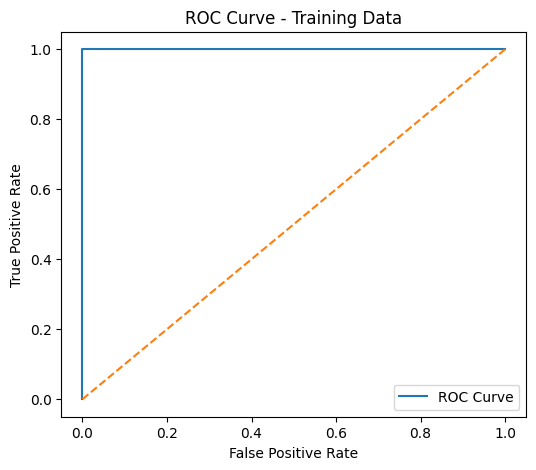

Training AUC: 1.0


In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_train, train_prob)

auc_score = roc_auc_score(y_train, train_prob)

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label='ROC Curve')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Training Data')
plt.legend()

plt.show()

print("Training AUC:", auc_score)

The training confusion matrix shows perfect classification, with all 60 other instances and all 9 bending instances classified correctly. The training AUC is 1.0.

However, the logistic regression output indicates complete separation and failure to converge. Therefore, the estimated coefficients and their p-values are unstable and should be interpreted with caution. This issue is discussed further in part 2(a)(vi).

### 2(a)(v) Test the Classifier on the Test Set

Use the same number of splits and the same selected features as the training model, then evaluate the classifier on the test set.

In [23]:
from sklearn.metrics import accuracy_score

test_rows = []
y_test = []

for folder in folders:
    folder_path = os.path.join(base_path, folder)
    files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

    for file in files:

        if folder in ['bending1', 'bending2']:
            if file not in ['dataset1.csv', 'dataset2.csv']:
                continue
        else:
            if file not in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                continue

        file_path = os.path.join(folder_path, file)

        if folder == 'bending2' and file == 'dataset4.csv':
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                sep=r'\s+'
            )
        else:
            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                usecols=range(7)
            )

        index_parts = np.array_split(np.arange(len(df)), best_l)

        row = []

        for indexes in index_parts:

            part = df.iloc[indexes]

            for column in column_names[1:]:

                row.extend([
                    part[column].min(),
                    part[column].max(),
                    part[column].mean(),
                    part[column].median(),
                    part[column].std(),
                    part[column].quantile(0.25),
                    part[column].quantile(0.75)
                ])

        test_rows.append(row)

        if folder in ['bending1', 'bending2']:
            y_test.append(1)
        else:
            y_test.append(0)

X_test_full = pd.DataFrame(
    test_rows,
    columns=feature_names_by_l[best_l - 1]
)

y_test = np.array(y_test)

print("Test set shape:", X_test_full.shape)
print("Test labels:", y_test.shape)

Test set shape: (19, 84)
Test labels: (19,)


#### Test Accuracy

In [24]:
X_test_selected = X_test_full[selected_features]

X_test_scaled = scaler.transform(X_test_selected)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=selected_features
)

X_test_logit = sm.add_constant(
    X_test_scaled,
    has_constant='add'
)

test_prob = logit_model.predict(X_test_logit)

test_pred = (test_prob >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, test_pred)

print("Cross-Validation Accuracy:", best_cv_accuracy)
print("Test Accuracy:", test_accuracy)

Cross-Validation Accuracy: 0.9714285714285715
Test Accuracy: 1.0


The 5-fold cross-validation accuracy is 0.9714, while the test accuracy is 1.0000. The test accuracy is slightly higher than the cross-validation accuracy, and the two values are reasonably close. This suggests that the classifier performs well on unseen test data. However, because complete separation was observed in the training data, the logistic regression parameter estimates may still be unstable despite the high test accuracy.

### 2(a)(vi) Class Separation and Logistic Regression Stability

The bending and other classes appear to be completely separated. The training confusion matrix shows perfect classification and the training AUC is 1.0.

The logistic regression output also reports complete separation and failure to converge. Under complete separation, the maximum likelihood estimates of the logistic regression coefficients do not have finite stable values. As a result, some coefficients and standard errors become extremely large, and the corresponding p-values are unreliable.

Therefore, the classes are sufficiently well separated to cause instability in the logistic regression parameter estimates.

### 2(a)(vii) Class Imbalance and Case-Control Sampling

The training data are imbalanced, with 9 bending instances and 60 other instances. To reduce the effect of class imbalance, case-control sampling is used by keeping all bending instances and randomly selecting the same number of other instances.

In [25]:
positive_index = np.where(y_train == 1)[0]
negative_index = np.where(y_train == 0)[0]

np.random.seed(1)

sampled_negative_index = np.random.choice(
    negative_index,
    size=len(positive_index),
    replace=False
)

balanced_index = np.concatenate([
    positive_index,
    sampled_negative_index
])

X_case_control = X_selected_scaled.iloc[balanced_index].reset_index(drop=True)
y_case_control = y_train[balanced_index]

print("Bending:", sum(y_case_control == 1))
print("Other:", sum(y_case_control == 0))

Bending: 9
Other: 9


#### Case-Control Logistic Regression

In [26]:
X_cc_logit = sm.add_constant(
    X_case_control,
    has_constant='add'
)

case_control_model = sm.Logit(
    y_case_control,
    X_cc_logit
).fit()

print(case_control_model.summary())

         Current function value: 0.000000
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   18
Model:                          Logit   Df Residuals:                       14
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        03:35:53   Log-Likelihood:            -5.2806e-09
converged:                      False   LL-Null:                       -12.477
Covariance Type:            nonrobust   LLR p-value:                 1.579e-05
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -86.0511   6.01e+04     -0.001      0.999   -1.18e+05    1.18e+05
median1_part1   -25.1317    2.5e+04     -0.001      0.99

/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local

#### Adjust the Intercept

In [27]:
original_probability = np.mean(y_train)
sample_probability = np.mean(y_case_control)

intercept_adjustment = (
    np.log(original_probability / (1 - original_probability))
    -
    np.log(sample_probability / (1 - sample_probability))
)

adjusted_parameters = case_control_model.params.copy()

adjusted_parameters['const'] = (
    adjusted_parameters['const']
    + intercept_adjustment
)

print("Adjusted Parameters:")
print(adjusted_parameters)

Adjusted Parameters:
const           -87.948258
median1_part1   -25.131734
min5_part1       71.280275
max5_part1       45.970426
dtype: float64


#### Confusion Matrix, ROC Curve, and AUC

In [28]:
X_full_logit = sm.add_constant(
    X_selected_scaled,
    has_constant='add'
)

linear_score = np.dot(
    X_full_logit,
    adjusted_parameters
)

adjusted_prob = 1 / (1 + np.exp(-linear_score))

adjusted_pred = (adjusted_prob >= 0.5).astype(int)

cc_confusion_matrix = confusion_matrix(
    y_train,
    adjusted_pred
)

cc_auc = roc_auc_score(
    y_train,
    adjusted_prob
)

print("Confusion Matrix:")
print(cc_confusion_matrix)

print("AUC:", cc_auc)

Confusion Matrix:
[[60  0]
 [ 0  9]]
AUC: 1.0


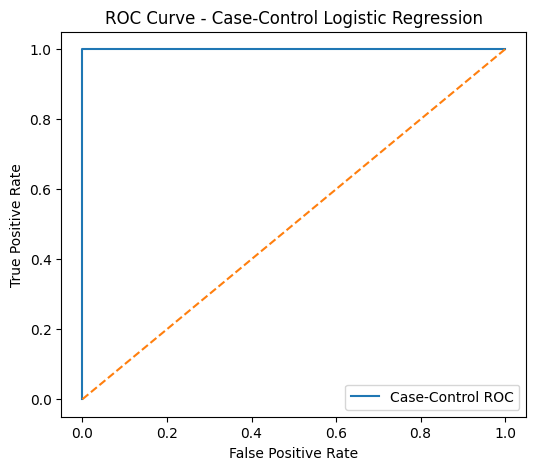

In [29]:
fpr_cc, tpr_cc, thresholds_cc = roc_curve(
    y_train,
    adjusted_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_cc,
    tpr_cc,
    label='Case-Control ROC'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Case-Control Logistic Regression')
plt.legend()

plt.show()

The original training data are imbalanced, with 9 bending instances and 60 other instances. Case-control sampling was used to create a balanced sample containing 9 bending and 9 other instances.

Because the sampling changes the class proportions, the intercept was adjusted to reflect the original proportion of bending observations. The slope coefficients do not require this prevalence correction.

The adjusted case-control model achieves a confusion matrix of

$$
\begin{bmatrix}
60 & 0 \\
0 & 9
\end{bmatrix}
$$

and an AUC of 1.0.

However, the case-control logistic regression still exhibits complete separation and does not converge. Therefore, although case-control sampling addresses the class imbalance, it does not eliminate the instability in the logistic regression coefficient estimates caused by complete separation.

## 2(b) Binary Classification Using L1-Penalized Logistic Regression

### 2(b)(i) Cross-Validation for l and C

Use L1-penalized logistic regression and 5-fold stratified cross-validation to determine the best combination of \(l\) and \(C\). The features are standardized before fitting the model.

In [30]:
from sklearn.model_selection import GridSearchCV

C_values = np.logspace(-4, 4, 20)

l1_results = []

for l in range(1, 21):

    X = X_by_l[l - 1]

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(
            penalty='l1',
            solver='liblinear',
            max_iter=2000
        ))
    ])

    parameter_grid = {
        'logreg__C': C_values
    }

    grid_search = GridSearchCV(
        pipeline,
        parameter_grid,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(X, y_train)

    best_C = grid_search.best_params_['logreg__C']
    best_score = grid_search.best_score_

    l1_results.append([
        l,
        best_C,
        best_score
    ])

l1_cv_table = pd.DataFrame(
    l1_results,
    columns=[
        'l',
        'C',
        'CV Accuracy'
    ]
)

l1_cv_table

,l,C,CV Accuracy
0,1,0.615848,0.985714
1,2,0.233572,0.957143
2,3,0.233572,0.957143
3,4,0.615848,0.971429
4,5,0.615848,0.928571
5,6,206.913808,0.941758
6,7,0.233572,0.928571
7,8,3792.690191,0.941758
8,9,0.233572,0.928571
9,10,78.475997,0.941758


#### Best l and C

In [31]:
best_l1_result = l1_cv_table.sort_values(
    by=['CV Accuracy', 'l'],
    ascending=[False, True]
).iloc[0]

best_l_l1 = int(best_l1_result['l'])
best_C_l1 = best_l1_result['C']
best_l1_cv_accuracy = best_l1_result['CV Accuracy']

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best CV Accuracy:", best_l1_cv_accuracy)

Best l: 1
Best C: 0.615848211066026
Best CV Accuracy: 0.9857142857142858


#### Final L1-Penalized Logistic Regression Model

In [32]:
X_l1_best = X_by_l[best_l_l1 - 1]

final_l1_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        penalty='l1',
        solver='liblinear',
        C=best_C_l1,
        max_iter=2000
    ))
])

final_l1_model.fit(
    X_l1_best,
    y_train
)

l1_coefficients = final_l1_model.named_steps['logreg'].coef_[0]

nonzero_features = X_l1_best.columns[
    l1_coefficients != 0
].tolist()

print("Number of non-zero features:", len(nonzero_features))
print("Selected features:")
print(nonzero_features)

Number of non-zero features: 5
Selected features:
['q3_1_part1', 'min5_part1', 'max5_part1', 'median6_part1', 'q1_6_part1']


The best L1-penalized logistic regression model uses \(l=1\) and \(C=0.6158\), with a 5-fold cross-validation accuracy of 0.9857.

The L1 penalty shrinks many coefficients exactly to zero. The final model retains 5 non-zero features, so L1 regularization performs feature selection automatically while fitting the classifier.

### 2(b)(ii) Comparison with Variable Selection

Because RFE was used as the permitted alternative variable-selection method in part 2(a)(iii), the L1-penalized model is compared with the RFE-based logistic regression model here.

In [33]:
comparison = pd.DataFrame({
    'Method': [
        'Logistic Regression with RFE',
        'L1-Penalized Logistic Regression'
    ],
    'Best l': [
        best_l,
        best_l_l1
    ],
    'Number of Selected Features': [
        best_p,
        len(nonzero_features)
    ],
    'CV Accuracy': [
        best_cv_accuracy,
        best_l1_cv_accuracy
    ]
})

comparison

,Method,Best l,Number of Selected Features,CV Accuracy
0,Logistic Regression with RFE,2,3,0.971429
1,L1-Penalized Logistic Regression,1,5,0.985714


The L1-penalized logistic regression performs slightly better than logistic regression with RFE. The best RFE model uses \(l = 2\) and 3 selected features, with a cross-validation accuracy of 0.9714. The best L1-penalized model uses \(l = 1\) and 5 non-zero features, with a higher cross-validation accuracy of 0.9857.

L1-penalized logistic regression is also easier to implement because feature selection is performed automatically by shrinking some coefficients exactly to zero. In contrast, RFE requires an additional recursive feature elimination procedure and cross-validation over the number of selected features.

Therefore, for this dataset, L1-penalized logistic regression provides both slightly better predictive performance and a simpler feature-selection procedure.

## 2(c) Multi-class Classification

### 2(c)(i) L1-Penalized Multinomial Logistic Regression

The activities are classified into seven classes: bending1, bending2, cycling, lying, sitting, standing, and walking.

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

base_path = '/content/AReM'

column_names = [
    'time',
    'avg_rss12',
    'var_rss12',
    'avg_rss13',
    'var_rss13',
    'avg_rss23',
    'var_rss23'
]

folders = [
    'bending1',
    'bending2',
    'cycling',
    'lying',
    'sitting',
    'standing',
    'walking'
]

print(folders)
print(os.path.exists(base_path))

['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
True


In [23]:
X_multi_by_l = []
y_multi_train = None

for l in range(1, 21):

    rows = []
    labels = []
    feature_names = []

    # Create feature names
    for part_number in range(1, l + 1):

        for series_number in range(1, 7):

            feature_names.extend([
                'min' + str(series_number) + '_part' + str(part_number),
                'max' + str(series_number) + '_part' + str(part_number),
                'mean' + str(series_number) + '_part' + str(part_number),
                'median' + str(series_number) + '_part' + str(part_number),
                'std' + str(series_number) + '_part' + str(part_number),
                'q1_' + str(series_number) + '_part' + str(part_number),
                'q3_' + str(series_number) + '_part' + str(part_number)
            ])

    # Read training data
    for folder in folders:

        folder_path = os.path.join(base_path, folder)

        files = sorted([
            file for file in os.listdir(folder_path)
            if file.endswith('.csv')
        ])

        for file in files:

            # Skip test files
            if folder in ['bending1', 'bending2']:

                if file in ['dataset1.csv', 'dataset2.csv']:
                    continue

            else:

                if file in [
                    'dataset1.csv',
                    'dataset2.csv',
                    'dataset3.csv'
                ]:
                    continue

            file_path = os.path.join(folder_path, file)

            # Special file
            if folder == 'bending2' and file == 'dataset4.csv':

                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    sep=r'\s+'
                )

            else:

                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    usecols=range(7)
                )

            # Split time series into l parts
            index_parts = np.array_split(
                np.arange(len(df)),
                l
            )

            row = []

            for indexes in index_parts:

                part = df.iloc[indexes]

                for column in column_names[1:]:

                    row.extend([
                        part[column].min(),
                        part[column].max(),
                        part[column].mean(),
                        part[column].median(),
                        part[column].std(),
                        part[column].quantile(0.25),
                        part[column].quantile(0.75)
                    ])

            rows.append(row)

            # Keep all 7 activity classes separate
            labels.append(folder)

    X_multi_by_l.append(
        pd.DataFrame(
            rows,
            columns=feature_names
        )
    )

    if y_multi_train is None:
        y_multi_train = np.array(labels)

print("Shape for l = 1:", X_multi_by_l[0].shape)
print()
print("Training class counts:")
print(pd.Series(y_multi_train).value_counts())

Shape for l = 1: (69, 42)

Training class counts:
cycling     12
sitting     12
lying       12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


#### Cross-Validation for l and C

In [24]:
C_values_multi = np.logspace(-3, 3, 10)

multi_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=1
)

multi_results = []

for l in range(1, 21):

    print("Testing l =", l)

    X = X_multi_by_l[l - 1]

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(
            penalty='l1',
            solver='saga',
            max_iter=5000,
            tol=0.01,
            random_state=1
        ))
    ])

    grid_search = GridSearchCV(
        model,
        {
            'logreg__C': C_values_multi
        },
        cv=multi_cv,
        scoring='accuracy',
        n_jobs=-1
    )

    grid_search.fit(
        X,
        y_multi_train
    )

    multi_results.append([
        l,
        grid_search.best_params_['logreg__C'],
        grid_search.best_score_
    ])

multi_cv_table = pd.DataFrame(
    multi_results,
    columns=[
        'l',
        'C',
        'CV Accuracy'
    ]
)

multi_cv_table

Testing l = 1
Testing l = 2
Testing l = 3
Testing l = 4
Testing l = 5
Testing l = 6
Testing l = 7
Testing l = 8
Testing l = 9
Testing l = 10
Testing l = 11
Testing l = 12
Testing l = 13
Testing l = 14
Testing l = 15
Testing l = 16
Testing l = 17
Testing l = 18
Testing l = 19
Testing l = 20


,l,C,CV Accuracy
0,1,0.464159,0.857843
1,2,46.415888,0.843954
2,3,2.154435,0.814542
3,4,46.415888,0.844771
4,5,46.415888,0.843954
5,6,46.415888,0.814542
6,7,10.000000,0.843137
7,8,46.415888,0.857843
8,9,215.443469,0.843137
9,10,46.415888,0.828431


#### Best l and C

In [25]:
best_multi_result = multi_cv_table.sort_values(
    by=['CV Accuracy', 'l'],
    ascending=[False, True]
).iloc[0]

best_multi_l = int(
    best_multi_result['l']
)

best_multi_C = best_multi_result['C']

best_multi_cv_accuracy = best_multi_result[
    'CV Accuracy'
]

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print("Best CV Accuracy:", best_multi_cv_accuracy)

Best l: 1
Best C: 0.46415888336127775
Best CV Accuracy: 0.857843137254902


#### Final L1-Penalized Multinomial Logistic Regression Model

In [26]:
X_multi_best = X_multi_by_l[
    best_multi_l - 1
]

final_multi_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        penalty='l1',
        solver='saga',
        C=best_multi_C,
        max_iter=5000,
        tol=0.01,
        random_state=1
    ))
])

final_multi_model.fit(
    X_multi_best,
    y_multi_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg',
                 LogisticRegression(C=np.float64(0.46415888336127775),
                                    max_iter=5000, penalty='l1', random_state=1,
                                    solver='saga', tol=0.01))])

#### Test Set

In [27]:
multi_test_rows = []
y_multi_test = []

for folder in folders:

    folder_path = os.path.join(
        base_path,
        folder
    )

    files = sorted([
        file for file in os.listdir(folder_path)
        if file.endswith('.csv')
    ])

    for file in files:

        # Keep only test files
        if folder in ['bending1', 'bending2']:

            if file not in [
                'dataset1.csv',
                'dataset2.csv'
            ]:
                continue

        else:

            if file not in [
                'dataset1.csv',
                'dataset2.csv',
                'dataset3.csv'
            ]:
                continue

        file_path = os.path.join(
            folder_path,
            file
        )

        if folder == 'bending2' and file == 'dataset4.csv':

            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                sep=r'\s+'
            )

        else:

            df = pd.read_csv(
                file_path,
                comment='#',
                header=None,
                names=column_names,
                usecols=range(7)
            )

        # Use the best l selected from training
        index_parts = np.array_split(
            np.arange(len(df)),
            best_multi_l
        )

        row = []

        for indexes in index_parts:

            part = df.iloc[indexes]

            for column in column_names[1:]:

                row.extend([
                    part[column].min(),
                    part[column].max(),
                    part[column].mean(),
                    part[column].median(),
                    part[column].std(),
                    part[column].quantile(0.25),
                    part[column].quantile(0.75)
                ])

        multi_test_rows.append(row)

        # Keep bending1 and bending2 separate
        y_multi_test.append(folder)

X_multi_test = pd.DataFrame(
    multi_test_rows,
    columns=X_multi_best.columns
)

y_multi_test = np.array(
    y_multi_test
)

print(
    "Test set shape:",
    X_multi_test.shape
)

print()

print(
    "Test class counts:"
)

print(
    pd.Series(
        y_multi_test
    ).value_counts()
)

Test set shape: (19, 42)

Test class counts:
cycling     3
sitting     3
lying       3
standing    3
walking     3
bending2    2
bending1    2
Name: count, dtype: int64


#### Test Error

In [28]:
multi_test_pred = final_multi_model.predict(
    X_multi_test
)

multi_test_accuracy = accuracy_score(
    y_multi_test,
    multi_test_pred
)

multi_test_error = (
    1 - multi_test_accuracy
)

print(
    "CV Accuracy:",
    best_multi_cv_accuracy
)

print(
    "Test Accuracy:",
    multi_test_accuracy
)

print(
    "Test Error:",
    multi_test_error
)

CV Accuracy: 0.857843137254902
Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684


#### Multiclass Confusion Matrix

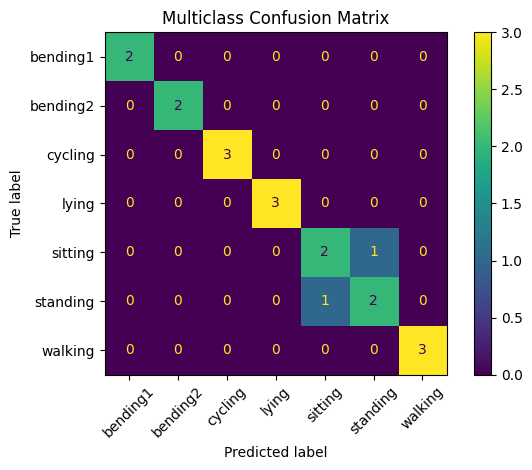

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_multi_test,
    multi_test_pred,
    xticks_rotation=45
)

plt.title(
    "Multiclass Confusion Matrix"
)

plt.tight_layout()
plt.show()

#### Multiclass ROC Curves and AUC

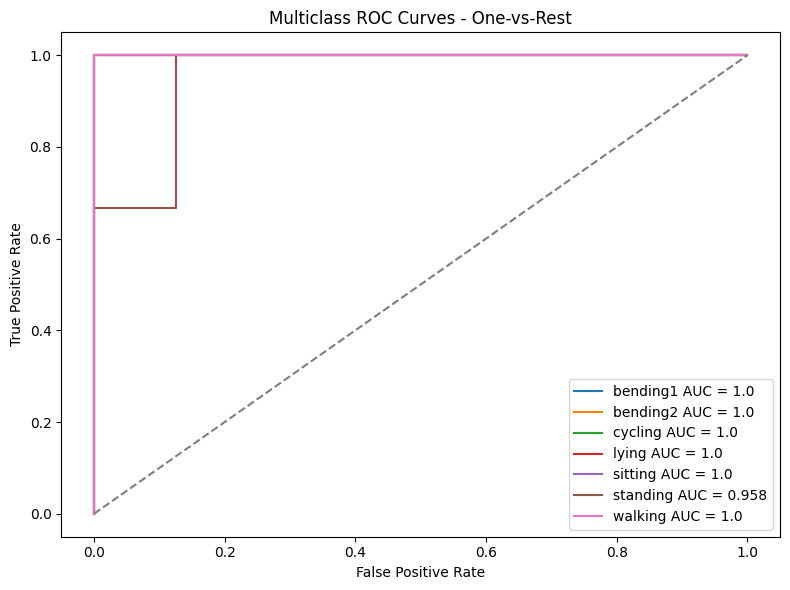

In [30]:
classes = final_multi_model.named_steps[
    'logreg'
].classes_

y_test_binary = label_binarize(
    y_multi_test,
    classes=classes
)

multi_test_prob = final_multi_model.predict_proba(
    X_multi_test
)

plt.figure(
    figsize=(8, 6)
)

for i in range(len(classes)):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        multi_test_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            classes[i]
            + ' AUC = '
            + str(round(class_auc, 3))
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel(
    'False Positive Rate'
)

plt.ylabel(
    'True Positive Rate'
)

plt.title(
    'Multiclass ROC Curves - One-vs-Rest'
)

plt.legend()
plt.tight_layout()
plt.show()

In [31]:
macro_auc = roc_auc_score(
    y_test_binary,
    multi_test_prob,
    average='macro'
)

print(
    "Macro-average AUC:",
    macro_auc
)

Macro-average AUC: 0.994047619047619


The best multinomial logistic regression model uses $l=1$ and $C=0.4642$. The 4-fold cross-validation accuracy is 0.8578.

On the test set, the model achieves an accuracy of 0.8947 and a test error of 0.1053. The macro-average AUC is 0.9940, indicating strong overall class-separation performance.

### 2(c)(ii) Naive Bayes Classification

Gaussian Naive Bayes and Multinomial Naive Bayes are used for the seven-class activity classification problem. Four-fold stratified cross-validation is used to select the best value of $l$ for each model.

#### Gaussian Naive Bayes

In [32]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

nb_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=1
)

gaussian_results = []

for l in range(1, 21):

    X = X_multi_by_l[l - 1]

    model = GaussianNB()

    scores = cross_val_score(
        model,
        X,
        y_multi_train,
        cv=nb_cv,
        scoring='accuracy',
        n_jobs=-1
    )

    gaussian_results.append([
        l,
        scores.mean()
    ])

gaussian_cv_table = pd.DataFrame(
    gaussian_results,
    columns=[
        'l',
        'CV Accuracy'
    ]
)

gaussian_cv_table

,l,CV Accuracy
0,1,0.784314
1,2,0.801471
2,3,0.653595
3,4,0.581699
4,5,0.597222
5,6,0.580882
6,7,0.565359
7,8,0.610294
8,9,0.566993
9,10,0.597222


In [33]:
best_gaussian_result = gaussian_cv_table.sort_values(
    by=['CV Accuracy', 'l'],
    ascending=[False, True]
).iloc[0]

best_gaussian_l = int(
    best_gaussian_result['l']
)

best_gaussian_cv_accuracy = best_gaussian_result[
    'CV Accuracy'
]

print("Gaussian NB Best l:", best_gaussian_l)
print(
    "Gaussian NB Best CV Accuracy:",
    best_gaussian_cv_accuracy
)

Gaussian NB Best l: 2
Gaussian NB Best CV Accuracy: 0.8014705882352942


#### Multinomial Naive Bayes

In [34]:
multinomial_results = []

for l in range(1, 21):

    X = X_multi_by_l[l - 1]

    model = MultinomialNB()

    scores = cross_val_score(
        model,
        X,
        y_multi_train,
        cv=nb_cv,
        scoring='accuracy',
        n_jobs=-1
    )

    multinomial_results.append([
        l,
        scores.mean()
    ])

multinomial_cv_table = pd.DataFrame(
    multinomial_results,
    columns=[
        'l',
        'CV Accuracy'
    ]
)

multinomial_cv_table

,l,CV Accuracy
0,1,0.827614
1,2,0.741013
2,3,0.726307
3,4,0.741013
4,5,0.727124
5,6,0.711601
6,7,0.725490
7,8,0.726307
8,9,0.696895
9,10,0.682190


In [35]:
best_multinomial_result = multinomial_cv_table.sort_values(
    by=['CV Accuracy', 'l'],
    ascending=[False, True]
).iloc[0]

best_multinomial_l = int(
    best_multinomial_result['l']
)

best_multinomial_cv_accuracy = best_multinomial_result[
    'CV Accuracy'
]

print(
    "Multinomial NB Best l:",
    best_multinomial_l
)

print(
    "Multinomial NB Best CV Accuracy:",
    best_multinomial_cv_accuracy
)

Multinomial NB Best l: 1
Multinomial NB Best CV Accuracy: 0.8276143790849673


#### Test Performance of Naive Bayes Models

In [36]:
X_multi_test_by_l = []

for l in range(1, 21):

    test_rows = []
    test_labels = []
    feature_names = []

    for part_number in range(1, l + 1):

        for series_number in range(1, 7):

            feature_names.extend([
                'min' + str(series_number) + '_part' + str(part_number),
                'max' + str(series_number) + '_part' + str(part_number),
                'mean' + str(series_number) + '_part' + str(part_number),
                'median' + str(series_number) + '_part' + str(part_number),
                'std' + str(series_number) + '_part' + str(part_number),
                'q1_' + str(series_number) + '_part' + str(part_number),
                'q3_' + str(series_number) + '_part' + str(part_number)
            ])

    for folder in folders:

        folder_path = os.path.join(
            base_path,
            folder
        )

        files = sorted([
            file for file in os.listdir(folder_path)
            if file.endswith('.csv')
        ])

        for file in files:

            if folder in ['bending1', 'bending2']:

                if file not in [
                    'dataset1.csv',
                    'dataset2.csv'
                ]:
                    continue

            else:

                if file not in [
                    'dataset1.csv',
                    'dataset2.csv',
                    'dataset3.csv'
                ]:
                    continue

            file_path = os.path.join(
                folder_path,
                file
            )

            if folder == 'bending2' and file == 'dataset4.csv':

                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    sep=r'\s+'
                )

            else:

                df = pd.read_csv(
                    file_path,
                    comment='#',
                    header=None,
                    names=column_names,
                    usecols=range(7)
                )

            index_parts = np.array_split(
                np.arange(len(df)),
                l
            )

            row = []

            for indexes in index_parts:

                part = df.iloc[indexes]

                for column in column_names[1:]:

                    row.extend([
                        part[column].min(),
                        part[column].max(),
                        part[column].mean(),
                        part[column].median(),
                        part[column].std(),
                        part[column].quantile(0.25),
                        part[column].quantile(0.75)
                    ])

            test_rows.append(row)

            # Keep all seven classes separate
            test_labels.append(folder)

    X_multi_test_by_l.append(
        pd.DataFrame(
            test_rows,
            columns=feature_names
        )
    )

y_multi_test = np.array(
    test_labels
)

print(
    "Number of test instances:",
    len(y_multi_test)
)

print(
    pd.Series(y_multi_test).value_counts()
)

Number of test instances: 19
cycling     3
sitting     3
lying       3
standing    3
walking     3
bending2    2
bending1    2
Name: count, dtype: int64


Number of test instances: 19

##### Gaussian Naive Bayes Test Error

In [37]:
gaussian_model = GaussianNB()

gaussian_model.fit(
    X_multi_by_l[best_gaussian_l - 1],
    y_multi_train
)

gaussian_pred = gaussian_model.predict(
    X_multi_test_by_l[best_gaussian_l - 1]
)

gaussian_prob = gaussian_model.predict_proba(
    X_multi_test_by_l[best_gaussian_l - 1]
)

gaussian_test_accuracy = accuracy_score(
    y_multi_test,
    gaussian_pred
)

gaussian_test_error = (
    1 - gaussian_test_accuracy
)

print(
    "Gaussian NB CV Accuracy:",
    best_gaussian_cv_accuracy
)

print(
    "Gaussian NB Test Accuracy:",
    gaussian_test_accuracy
)

print(
    "Gaussian NB Test Error:",
    gaussian_test_error
)

Gaussian NB CV Accuracy: 0.8014705882352942
Gaussian NB Test Accuracy: 0.631578947368421
Gaussian NB Test Error: 0.368421052631579


#### Gaussian Naive Bayes Confusion Matrix

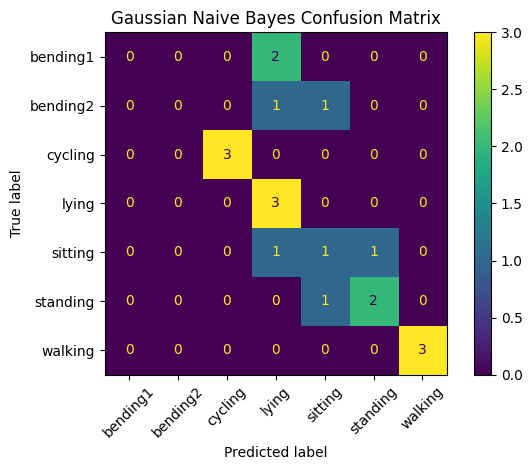

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_multi_test,
    gaussian_pred,
    xticks_rotation=45
)

plt.title(
    "Gaussian Naive Bayes Confusion Matrix"
)

plt.tight_layout()
plt.show()

#### Gaussian Naive Bayes ROC Curves and AUC

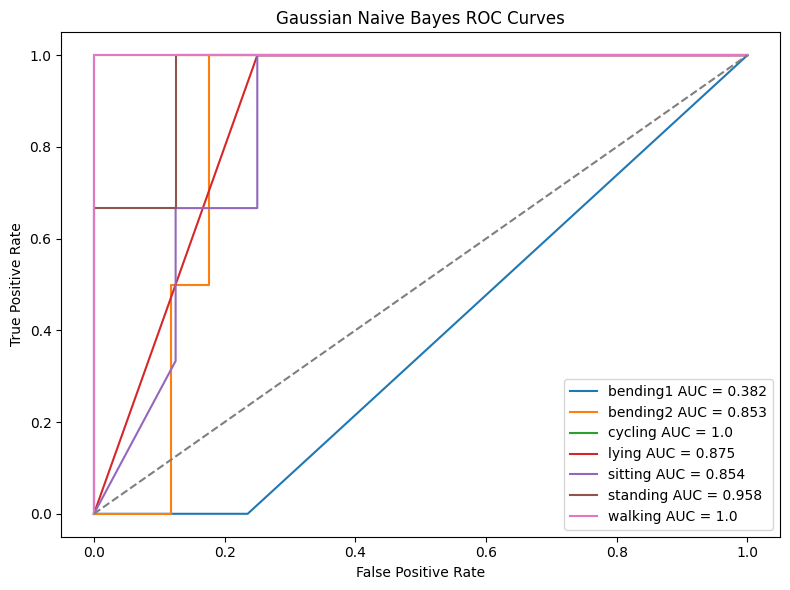

In [39]:
gaussian_classes = gaussian_model.classes_

gaussian_test_binary = label_binarize(
    y_multi_test,
    classes=gaussian_classes
)

plt.figure(
    figsize=(8, 6)
)

for i in range(len(gaussian_classes)):

    fpr, tpr, thresholds = roc_curve(
        gaussian_test_binary[:, i],
        gaussian_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            gaussian_classes[i]
            + ' AUC = '
            + str(round(class_auc, 3))
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(
    'Gaussian Naive Bayes ROC Curves'
)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
gaussian_macro_auc = roc_auc_score(
    gaussian_test_binary,
    gaussian_prob,
    average='macro'
)

print(
    "Gaussian NB Macro-average AUC:",
    gaussian_macro_auc
)

Gaussian NB Macro-average AUC: 0.8461134453781513


##### Multinomial Naive Bayes Test Error

In [41]:
multinomial_model = MultinomialNB()

multinomial_model.fit(
    X_multi_by_l[best_multinomial_l - 1],
    y_multi_train
)

multinomial_pred = multinomial_model.predict(
    X_multi_test_by_l[
        best_multinomial_l - 1
    ]
)

multinomial_prob = multinomial_model.predict_proba(
    X_multi_test_by_l[
        best_multinomial_l - 1
    ]
)

multinomial_test_accuracy = accuracy_score(
    y_multi_test,
    multinomial_pred
)

multinomial_test_error = (
    1 - multinomial_test_accuracy
)

print(
    "Multinomial NB CV Accuracy:",
    best_multinomial_cv_accuracy
)

print(
    "Multinomial NB Test Accuracy:",
    multinomial_test_accuracy
)

print(
    "Multinomial NB Test Error:",
    multinomial_test_error
)

Multinomial NB CV Accuracy: 0.8276143790849673
Multinomial NB Test Accuracy: 0.8947368421052632
Multinomial NB Test Error: 0.10526315789473684


#### Multinomial Naive Bayes Confusion Matrix

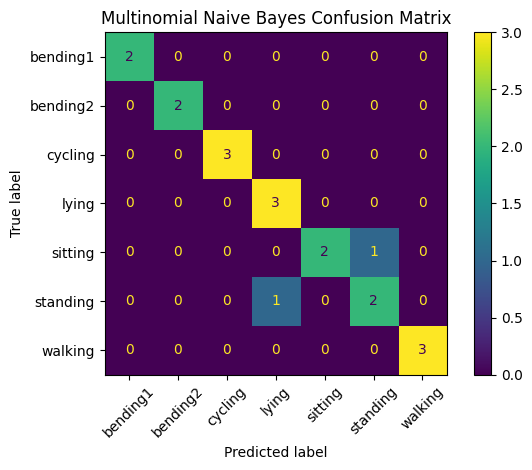

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_multi_test,
    multinomial_pred,
    xticks_rotation=45
)

plt.title(
    "Multinomial Naive Bayes Confusion Matrix"
)

plt.tight_layout()
plt.show()

#### Multinomial Naive Bayes ROC Curves and AUC

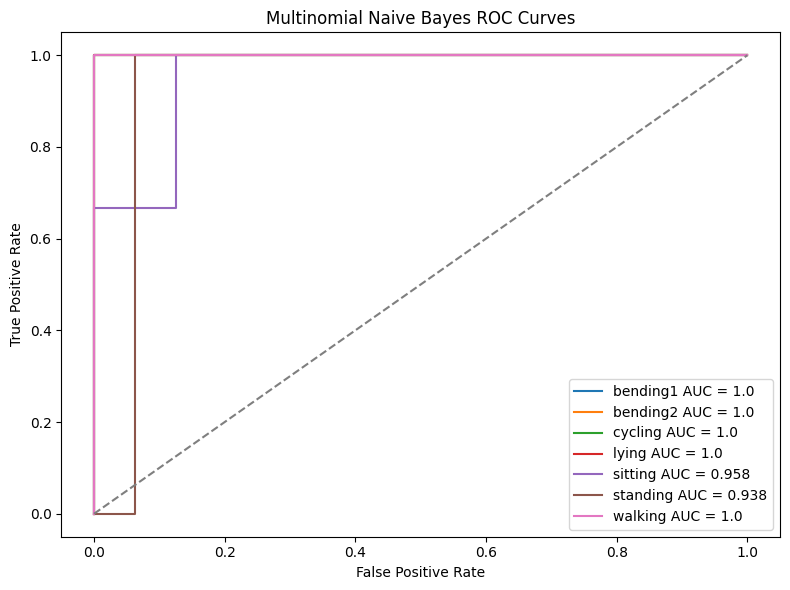

In [43]:
multinomial_classes = multinomial_model.classes_

multinomial_test_binary = label_binarize(
    y_multi_test,
    classes=multinomial_classes
)

plt.figure(
    figsize=(8, 6)
)

for i in range(len(multinomial_classes)):

    fpr, tpr, thresholds = roc_curve(
        multinomial_test_binary[:, i],
        multinomial_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            multinomial_classes[i]
            + ' AUC = '
            + str(round(class_auc, 3))
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(
    'Multinomial Naive Bayes ROC Curves'
)
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
multinomial_macro_auc = roc_auc_score(
    multinomial_test_binary,
    multinomial_prob,
    average='macro'
)

print(
    "Multinomial NB Macro-average AUC:",
    multinomial_macro_auc
)

Multinomial NB Macro-average AUC: 0.9851190476190476


In [45]:
naive_bayes_comparison = pd.DataFrame({
    'Method': [
        'Gaussian Naive Bayes',
        'Multinomial Naive Bayes'
    ],
    'Best l': [
        best_gaussian_l,
        best_multinomial_l
    ],
    'CV Accuracy': [
        best_gaussian_cv_accuracy,
        best_multinomial_cv_accuracy
    ],
    'Test Accuracy': [
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    'Test Error': [
        gaussian_test_error,
        multinomial_test_error
    ],
    'Macro AUC': [
        gaussian_macro_auc,
        multinomial_macro_auc
    ]
})

naive_bayes_comparison

,Method,Best l,CV Accuracy,Test Accuracy,Test Error,Macro AUC
0,Gaussian Naive Bayes,2,0.801471,0.631579,0.368421,0.846113
1,Multinomial Naive Bayes,1,0.827614,0.894737,0.105263,0.985119


Gaussian Naive Bayes performs worse than Multinomial Naive Bayes on this dataset. Gaussian Naive Bayes has a test error of 0.3684 and a macro-average AUC of 0.8461, while Multinomial Naive Bayes has a much lower test error of 0.1053 and a higher macro-average AUC of 0.9851.

Therefore, Multinomial Naive Bayes provides better multiclass classification performance than Gaussian Naive Bayes for this dataset.

### 2(c)(iii) Comparison of Multiclass Classification Methods

In [46]:
multiclass_comparison = pd.DataFrame({
    'Method': [
        'L1 Multinomial Logistic Regression',
        'Gaussian Naive Bayes',
        'Multinomial Naive Bayes'
    ],

    'CV Accuracy': [
        best_multi_cv_accuracy,
        best_gaussian_cv_accuracy,
        best_multinomial_cv_accuracy
    ],

    'Test Accuracy': [
        multi_test_accuracy,
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],

    'Test Error': [
        multi_test_error,
        gaussian_test_error,
        multinomial_test_error
    ],

    'Macro AUC': [
        macro_auc,
        gaussian_macro_auc,
        multinomial_macro_auc
    ]
})

multiclass_comparison

,Method,CV Accuracy,Test Accuracy,Test Error,Macro AUC
0,L1 Multinomial Logistic Regression,0.857843,0.894737,0.105263,0.994048
1,Gaussian Naive Bayes,0.801471,0.631579,0.368421,0.846113
2,Multinomial Naive Bayes,0.827614,0.894737,0.105263,0.985119


The L1-penalized multinomial logistic regression and Multinomial Naive Bayes both achieve a test accuracy of 0.8947 and a test error of 0.1053.

However, the L1-penalized multinomial logistic regression has a higher cross-validation accuracy (0.8578 vs. 0.8276) and a higher macro-average AUC (0.9940 vs. 0.9851).

Gaussian Naive Bayes performs substantially worse, with a test accuracy of 0.6316 and a test error of 0.3684.

Therefore, the L1-penalized multinomial logistic regression provides the best overall multiclass classification performance for this problem.

## 3. ISLR 4.8.3

For class $k$, assume

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

The density of $X$ in class $k$ is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Using Bayes' rule, the Bayes classifier assigns an observation $x$ to the class with the largest

$$
\pi_k f_k(x),
$$

where $\pi_k$ is the prior probability for class $k$.

Taking the logarithm and dropping the constant term, the discriminant function is

$$
\delta_k(x)
=
\log(\pi_k)
-
\log(\sigma_k)
-
\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term,

$$
\delta_k(x)
=
\log(\pi_k)
-
\log(\sigma_k)
-
\frac{x^2-2\mu_kx+\mu_k^2}{2\sigma_k^2}.
$$

Therefore,

$$
\delta_k(x)
=
-\frac{1}{2\sigma_k^2}x^2
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log(\sigma_k)
+
\log(\pi_k).
$$

The discriminant function contains an $x^2$ term whose coefficient depends on the class-specific variance $\sigma_k^2$. Therefore, when the variances are different across classes, the quadratic terms do not cancel.

For two classes $k$ and $l$, the decision boundary is obtained by setting

$$
\delta_k(x)=\delta_l(x).
$$

This gives an equation of the form

$$
ax^2+bx+c=0.
$$

In general,

$$
a
=
\frac{1}{2\sigma_l^2}
-
\frac{1}{2\sigma_k^2}
\neq 0.
$$

Therefore, the Bayes decision boundary is not linear in $x$; it is quadratic.

If all class variances were equal, the $x^2$ terms would cancel and the classifier would become linear. Since QDA allows different class-specific variances, the Bayes classifier is quadratic.

## 4. ISLR 4.8.7

Let

- $Y = 1$ denote that the company issues a dividend.
- $Y = 0$ denote that the company does not issue a dividend.

The prior probabilities are

$$
P(Y=1)=0.8
$$

and

$$
P(Y=0)=0.2.
$$

The class means and common variance are

$$
\mu_1=10, \qquad \mu_0=0, \qquad \sigma^2=36.
$$

Using Bayes' theorem,

$$
P(Y=1 \mid X=4)
=
\frac{P(Y=1)f_1(4)}
{P(Y=1)f_1(4)+P(Y=0)f_0(4)}.
$$

For a normal distribution,

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma^2}
\right).
$$

For the dividend class,

$$
f_1(4)
=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(
-\frac{(4-10)^2}{2(36)}
\right).
$$

For the non-dividend class,

$$
f_0(4)
=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(
-\frac{(4-0)^2}{2(36)}
\right).
$$

Since the normalizing constants are the same, they cancel in Bayes' formula. Therefore,

$$
P(Y=1 \mid X=4)
=
\frac{
0.8e^{-36/72}
}{
0.8e^{-36/72}
+
0.2e^{-16/72}
}.
$$

Thus,

$$
P(Y=1 \mid X=4)
\approx 0.7519.
$$

Therefore, the probability that the company will issue a dividend this year is approximately

$$
\boxed{75.19\%}.
$$

## AI Assistance Disclosure

I used OpenAI's ChatGPT as a learning and programming assistant for selected parts of this assignment. AI assistance was primarily used for understanding statistical concepts, reviewing my implementation, debugging code, and improving explanations. I ran and reviewed the code and outputs in my notebook before submission.

The main areas where AI assistance was used were:

- **Binary logistic regression and model selection:** assistance with implementing and reviewing recursive feature elimination, stratified cross-validation, feature selection, and the selection of the best values of $l$ and $p$.
- **Logistic regression diagnostics:** assistance with interpreting complete separation, unstable coefficient estimates, ROC/AUC results, and case-control sampling with intercept adjustment.
- **L1-penalized logistic regression:** assistance with setting up cross-validation over $l$ and the regularization parameter $C$, and comparing L1 regularization with RFE-based variable selection.
- **Multiclass classification:** assistance with correctly treating the seven activity folders as seven separate classes, implementing L1-penalized multinomial logistic regression, Gaussian Naive Bayes, and Multinomial Naive Bayes, and comparing multiclass confusion matrices, test errors, and ROC/AUC results.
- **ISLR exercises:** assistance with checking the mathematical derivation for the QDA decision boundary and verifying the Bayes probability calculation in ISLR 4.8.7.
- **Final review:** assistance with checking the notebook for consistency between code, outputs, and written conclusions.

### Representative Prompts Used

1. "Check my implementation of 5-fold cross-validation and RFE for selecting the best pair of $l$ and $p$ in logistic regression. Explain whether the feature-selection procedure causes data leakage."

2. "Explain why my logistic regression output reports complete separation and does not converge, even though the confusion matrix and AUC are perfect."

3. "Check my case-control sampling method for the imbalanced bending versus other classification problem and verify the intercept adjustment."

4. "Help me implement L1-penalized logistic regression with cross-validation over both the number of time-series splits $l$ and the regularization parameter $C$."

5. "Review the multiclass section of my homework. Should bending1 and bending2 be combined or treated as separate activity classes? Help me correct the multinomial logistic regression and Naive Bayes code."

6. "Check my derivation showing why QDA produces a quadratic decision boundary when class variances are different, and verify my Bayes calculation for ISLR 4.8.7."

### AI Citation

OpenAI. *ChatGPT*, responses to prompts concerning DSCI 552 Homework 4, 18 Oct. 2026, chatgpt.com.